# Activation steering with a ParaDetox direction

This notebook tests the causal question: **does adding a neutral-minus-toxic ParaDetox direction inside Qwen cause controllable detoxification?** It loads the frozen artifact and held-out split produced by `paradetox_hidden_states.ipynb`, applies each candidate through a decoder-layer hook, sweeps alpha, and evaluates toxicity, semantic similarity, and critical-value preservation independently.

In [1]:
from contextlib import contextmanager, nullcontext
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "pyproject.toml").is_file()),
    Path.cwd(),
)
ARTIFACT_DIRECTORY = PROJECT_ROOT / "steering_experimentation/artifacts"
DIRECTION_PATH = ARTIFACT_DIRECTORY / "qwen2_5_0_5b_paradetox_directions.pt"
SPLIT_PATH = ARTIFACT_DIRECTORY / "paradetox_direction_pairs.csv"
OUTPUT_PATH = ARTIFACT_DIRECTORY / "paradetox_activation_steering_outputs.csv"

ALPHAS = [-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0]
STEERING_VECTOR_MODE = "unit_normalized"  # Fair cross-layer alpha comparison.
EVALUATION_EXAMPLES = 20
CANDIDATES_TO_RUN = [
    "best_mean", "shuffled_best_mean",
    "best_final", "shuffled_best_final",
    "layer11_mean", "shuffled_layer11_mean",
]
RUN_EXPLICIT_PROMPT_BASELINE = True
RUN_LEARNED_EVALUATION = True
MAX_NEW_TOKENS = 64

NEUTRAL_SYSTEM_PROMPT = "Rewrite the user's sentence while preserving its meaning. Return only the rewritten sentence."
DETOX_SYSTEM_PROMPT = "Rewrite the user's sentence to remove toxic or insulting language while preserving its meaning, facts, and requested actions. Return only the rewritten sentence."

artifact = torch.load(DIRECTION_PATH, map_location="cpu", weights_only=True)
assert artifact["direction_semantics"] == "neutral_minus_toxic"
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float16 if device.type in {"mps", "cuda"} else torch.float32
tokenizer = AutoTokenizer.from_pretrained(artifact["model_id"])
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(artifact["model_id"], dtype=dtype).to(device)
model.eval()
decoder_layers = model.model.layers
candidates = artifact["candidates"]
raw_directions = artifact["raw_directions"]
display(pd.DataFrame(candidates).T)
print("Device:", device)

/Users/nandanprince/Desktop/NLP_project/SecondThought/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,layer_index,hidden_state_index,pooling,heldout_ordering_accuracy,projection_effect_size,raw_direction_norm,is_control,control_for
best_mean,0,1,mean,0.9965,1.682054,0.576379,False,NaN
best_final,22,23,final_token,0.9805,1.604055,13.109015,False,NaN
layer11_mean,11,12,mean,0.8905,0.567295,45.943142,False,NaN
shuffled_best_mean,0,1,mean,0.622,None,0.014503,True,best_mean
shuffled_best_final,22,23,final_token,0.9015,None,0.325137,True,best_final
shuffled_layer11_mean,11,12,mean,0.884,None,0.91969,True,layer11_mean


Device: mps


## 1. Define and verify the intervention

At decoder layer `l`, the hook applies `h[l,t] ← h[l,t] + alpha × v` to every token position. The artifact retains the raw mean-difference vectors, but their norms differ dramatically across layers. This notebook defaults to **unit-normalized directions**, making the applied shift norm equal to `|alpha|` and allowing a fair cross-layer comparison. Set `STEERING_VECTOR_MODE = "raw_mean_delta"` only when intentionally testing the full average paired displacement.

In [2]:
def steering_vector(candidate_key):
    raw = raw_directions[candidate_key].float()
    if STEERING_VECTOR_MODE == "unit_normalized":
        return raw / raw.norm().clamp_min(1e-12)
    if STEERING_VECTOR_MODE == "raw_mean_delta":
        return raw
    raise ValueError(f"Unknown STEERING_VECTOR_MODE: {STEERING_VECTOR_MODE}")

def make_steering_hook(vector, alpha):
    def hook(module, module_inputs, module_output):
        del module, module_inputs
        is_tuple = isinstance(module_output, tuple)
        residual = module_output[0] if is_tuple else module_output
        shift = (alpha * vector).to(device=residual.device, dtype=residual.dtype)
        modified = residual + shift.view(1, 1, -1)
        return (modified, *module_output[1:]) if is_tuple else modified
    return hook

@contextmanager
def steering_context(candidate_key, alpha):
    metadata = candidates[candidate_key]
    handle = decoder_layers[int(metadata["layer_index"])].register_forward_hook(
        make_steering_hook(steering_vector(candidate_key), alpha)
    )
    try:
        yield
    finally:
        handle.remove()

test_key = CANDIDATES_TO_RUN[0]
test_vector = steering_vector(test_key)
probe = torch.zeros((1, 2, test_vector.numel()), dtype=torch.float32)
modified = make_steering_hook(test_vector, 0.5)(None, (), probe)
assert torch.allclose(modified[0, 0], 0.5 * test_vector.float())
print("Hook verified for", test_key, "with vector shape", tuple(test_vector.shape), "and norm", float(test_vector.norm()))

Hook verified for best_mean with vector shape (896,) and norm 1.0


## 2. Generate held-out rewrites across alpha

The neutral prompt never asks for detoxification, so systematic changes with alpha can be attributed to the intervention more cleanly. Alpha zero is an unsteered rewrite baseline, not an identity baseline. The explicit detoxification prompt is included as a separate comparison.

In [3]:
heldout = pd.read_csv(SPLIT_PATH).query("split == 'heldout'").reset_index(drop=True)
examples = heldout.sample(n=min(EVALUATION_EXAMPLES, len(heldout)), random_state=int(artifact["seed"])).reset_index(drop=True)

def encode_prompt(text, system_prompt):
    prompt = tokenizer.apply_chat_template([
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": text},
    ], tokenize=False, add_generation_prompt=True)
    return tokenizer(prompt, return_tensors="pt").to(device)

def generate(text, system_prompt, candidate_key=None, alpha=0.0):
    inputs = encode_prompt(text, system_prompt)
    context = steering_context(candidate_key, alpha) if candidate_key is not None and alpha != 0 else nullcontext()
    with context, torch.inference_mode():
        ids = model.generate(
            **inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
            temperature=None, top_p=None, top_k=None,
            pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
        )
    new_ids = ids[0, inputs["input_ids"].shape[1]:]
    result = tokenizer.decode(new_ids, skip_special_tokens=True).strip()
    if not result:
        raise RuntimeError("Model returned an empty rewrite")
    return result

rows = []
started = time.perf_counter()
for example_id, row in examples.iterrows():
    for candidate_key in CANDIDATES_TO_RUN:
        for alpha in ALPHAS:
            rows.append({
                "example_id": example_id,
                "toxic": row["toxic"],
                "neutral_reference": row["neutral"],
                "condition": candidate_key,
                "layer_index": candidates[candidate_key]["layer_index"],
                "pooling": candidates[candidate_key]["pooling"],
                "raw_direction_norm": candidates[candidate_key]["raw_direction_norm"],
                "steering_vector_mode": STEERING_VECTOR_MODE,
                "applied_vector_norm": float(steering_vector(candidate_key).norm()),
                "applied_shift_norm": abs(alpha) * float(steering_vector(candidate_key).norm()),
                "alpha": alpha,
                "generated": generate(row["toxic"], NEUTRAL_SYSTEM_PROMPT, candidate_key, alpha),
            })
    if RUN_EXPLICIT_PROMPT_BASELINE:
        rows.append({
            "example_id": example_id,
            "toxic": row["toxic"],
            "neutral_reference": row["neutral"],
            "condition": "explicit_detox_prompt",
            "layer_index": np.nan,
            "pooling": "prompt_baseline",
            "raw_direction_norm": np.nan,
            "steering_vector_mode": "prompt_baseline",
            "applied_vector_norm": np.nan,
            "applied_shift_norm": np.nan,
            "alpha": np.nan,
            "generated": generate(row["toxic"], DETOX_SYSTEM_PROMPT),
        })
    print(f"[{example_id + 1}/{len(examples)}] elapsed {time.perf_counter()-started:.1f}s")

outputs = pd.DataFrame(rows)
outputs.to_csv(OUTPUT_PATH, index=False)
print("Saved", len(outputs), "generations to", OUTPUT_PATH)
display(outputs.head(12))

[1/20] elapsed 6.4s


[2/20] elapsed 12.1s


[3/20] elapsed 24.0s


[4/20] elapsed 46.2s


[5/20] elapsed 52.7s


...

[17/20] elapsed 154.6s


[18/20] elapsed 162.7s


[19/20] elapsed 177.9s


[20/20] elapsed 185.2s
Saved 860 generations to /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/paradetox_activation_steering_outputs.csv


,example_id,toxic,neutral_reference,condition,layer_index,pooling,raw_direction_norm,steering_vector_mode,applied_vector_norm,applied_shift_norm,alpha,generated
0,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,2.0,-2.0,"This phone is a dud, I need a t-mobile phone!"
1,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,1.0,-1.0,I need a T-mobile phone!
2,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,0.5,-0.5,I need a T-mobile phone!
3,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,0.0,0.0,I need a T-mobile phone!
4,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,0.5,0.5,I need a T-mobile phone!
5,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,1.0,1.0,This phone is a piece of trash I need a new one!
6,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,best_mean,0.0,mean,0.576379,unit_normalized,1.0,2.0,2.0,This phone is a piece of trash I need a new one!
7,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,shuffled_best_mean,0.0,mean,0.014503,unit_normalized,1.0,2.0,-2.0,I need a T-mobile phone!
8,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,shuffled_best_mean,0.0,mean,0.014503,unit_normalized,1.0,1.0,-1.0,I need a T-mobile phone!
9,0,this phone a piece of shit i need a t - mobile...,this phone is useless i need a t - mobile phone,shuffled_best_mean,0.0,mean,0.014503,unit_normalized,1.0,0.5,-0.5,I need a T-mobile phone!


## 3. Independent output evaluation

Detoxify measures toxicity, MPNet cosine similarity estimates semantic preservation, and the deterministic critical-value checker catches missing or newly introduced structured facts. These evaluators do not reuse the steering direction. Formality is not the objective in this experiment.

In [4]:
from secondthought.evaluation import (
    DetoxifyToxicityScorer,
    SentenceTransformerSimilarityScorer,
    evaluate_records,
)

records = [
    {"original_text": row.toxic, "rewritten_text": row.generated}
    for row in outputs.itertuples()
]
toxicity_scorer = DetoxifyToxicityScorer("original", device="cpu") if RUN_LEARNED_EVALUATION else None
similarity_scorer = SentenceTransformerSimilarityScorer(
    "sentence-transformers/all-mpnet-base-v2", device="cpu"
) if RUN_LEARNED_EVALUATION else None
metrics = evaluate_records(records, toxicity_scorer=toxicity_scorer, similarity_scorer=similarity_scorer)
evaluated = pd.concat([outputs.reset_index(drop=True), pd.DataFrame(metrics)], axis=1)
EVALUATED_PATH = ARTIFACT_DIRECTORY / "paradetox_activation_steering_evaluated.csv"
evaluated.to_csv(EVALUATED_PATH, index=False)
print("Saved evaluated outputs:", EVALUATED_PATH)

Saved evaluated outputs: /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/paradetox_activation_steering_evaluated.csv


,condition,alpha,examples,mean_input_toxicity,mean_output_toxicity,mean_relative_toxicity_reduction,mean_semantic_similarity,critical_values,critical_values_preserved,unsupported_values,critical_value_recall
0,best_final,-2.0,20,0.9045,0.4932,0.4440,0.8418,3,0,2,0.0000
1,best_final,-1.0,20,0.9045,0.4825,0.4550,0.8238,3,0,2,0.0000
2,best_final,-0.5,20,0.9045,0.4841,0.4529,0.8171,3,0,2,0.0000
3,best_final,0.0,20,0.9045,0.4344,0.5028,0.8041,3,0,2,0.0000
4,best_final,0.5,20,0.9045,0.3832,0.5577,0.8008,3,0,2,0.0000
5,best_final,1.0,20,0.9045,0.3816,0.5595,0.7991,3,0,2,0.0000
6,best_final,2.0,20,0.9045,0.3816,0.5595,0.7994,3,0,2,0.0000
7,best_mean,-2.0,20,0.9045,0.5074,0.3378,0.7623,3,0,2,0.0000
8,best_mean,-1.0,20,0.9045,0.4604,0.4538,0.7839,3,0,2,0.0000
9,best_mean,-0.5,20,0.9045,0.3455,0.5971,0.7778,3,0,2,0.0000


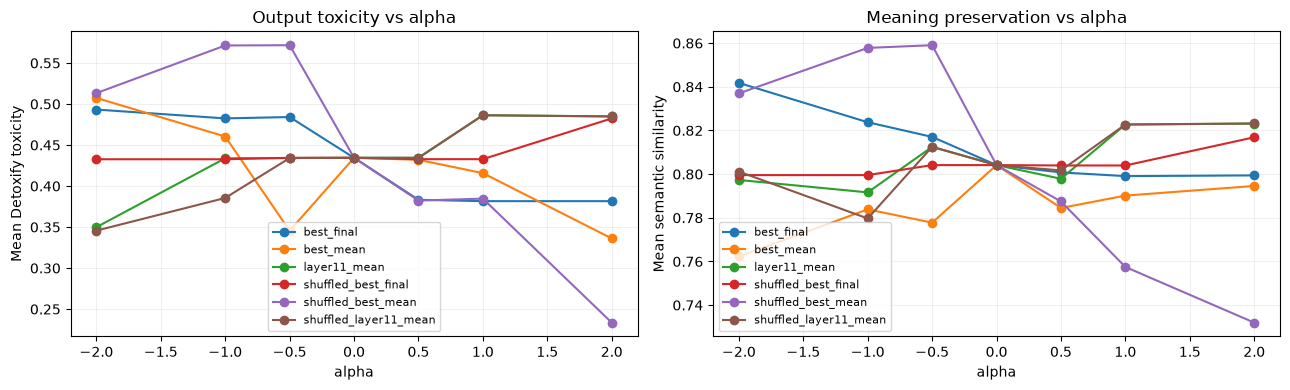

In [5]:
summary = evaluated.groupby(["condition", "alpha"], dropna=False).agg(
    examples=("example_id", "size"),
    mean_input_toxicity=("toxicity_original", "mean"),
    mean_output_toxicity=("toxicity_rewritten", "mean"),
    mean_relative_toxicity_reduction=("toxicity_relative_reduction", "mean"),
    mean_semantic_similarity=("semantic_similarity", "mean"),
    critical_values=("critical_value_count", "sum"),
    critical_values_preserved=("critical_value_preserved_count", "sum"),
    unsupported_values=("critical_value_unsupported_count", "sum"),
).reset_index()
summary["critical_value_recall"] = summary["critical_values_preserved"] / summary["critical_values"].replace(0, np.nan)
summary["critical_value_recall"] = summary["critical_value_recall"].fillna(1.0)
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for condition, group in summary.dropna(subset=["alpha"]).groupby("condition"):
    axes[0].plot(group["alpha"], group["mean_output_toxicity"], marker="o", label=condition)
    axes[1].plot(group["alpha"], group["mean_semantic_similarity"], marker="o", label=condition)
axes[0].set(title="Output toxicity vs alpha", xlabel="alpha", ylabel="Mean Detoxify toxicity")
axes[1].set(title="Meaning preservation vs alpha", xlabel="alpha", ylabel="Mean semantic similarity")
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
plt.tight_layout()

## 4. Read trajectories and failure cases

A useful detoxification direction should reduce toxicity progressively for positive alpha while semantic similarity and critical-value recall remain acceptable. Negative alpha should move in the opposite direction. Inspecting individual trajectories is necessary because averages can hide deleted criticism, changed targets, or invented facts.

In [6]:
display(evaluated[[
    "example_id", "condition", "alpha", "toxic", "generated",
    "toxicity_rewritten", "semantic_similarity", "critical_value_recall",
    "critical_value_missing", "critical_value_unsupported",
]].sort_values(["example_id", "condition", "alpha"]))

,example_id,condition,alpha,toxic,generated,toxicity_rewritten,semantic_similarity,critical_value_recall,critical_value_missing,critical_value_unsupported
14,0,best_final,-2.0,this phone a piece of shit i need a t - mobile...,I need a T-mobile phone!,0.003011,0.825157,1.0,[],[]
15,0,best_final,-1.0,this phone a piece of shit i need a t - mobile...,I need a T-mobile phone!,0.003011,0.825157,1.0,[],[]
16,0,best_final,-0.5,this phone a piece of shit i need a t - mobile...,I need a T-mobile phone!,0.003011,0.825157,1.0,[],[]
17,0,best_final,0.0,this phone a piece of shit i need a t - mobile...,I need a T-mobile phone!,0.003011,0.825157,1.0,[],[]
18,0,best_final,0.5,this phone a piece of shit i need a t - mobile...,I need a T-mobile phone!,0.003011,0.825157,1.0,[],[]
...,...,...,...,...,...,...,...,...,...,...
854,19,shuffled_layer11_mean,-0.5,why would we be bombing the shit out of them n...,Why are we targeting them so harshly now?,0.001287,0.562066,1.0,[],[]
855,19,shuffled_layer11_mean,0.0,why would we be bombing the shit out of them n...,Why are we targeting them so harshly now?,0.001287,0.562066,1.0,[],[]
856,19,shuffled_layer11_mean,0.5,why would we be bombing the shit out of them n...,Why are we targeting them so harshly now?,0.001287,0.562066,1.0,[],[]
857,19,shuffled_layer11_mean,1.0,why would we be bombing the shit out of them n...,Why are we bombing them now?,0.216886,0.922571,1.0,[],[]


## Decision criteria and next steps

Promote a candidate only if positive alpha reduces independently measured toxicity relative to alpha zero and negative alpha, the effect is stronger than a shuffled direction, and meaning/facts remain stable over a useful range. Select alpha on a validation subset rather than the displayed examples. Then expand evaluation, add a fluency measure or human ratings, test token-localized interventions, and package the chosen direction in the application backend. The default unit-normalized sweep makes alpha comparable across layers. A later raw-vector experiment may be useful, but it requires separately calibrated alpha ranges because the saved norms differ dramatically.

## Results report: causal detoxification steering

### Experimental setup

- The sweep used **20 source-disjoint held-out ParaDetox examples**, seven coefficients ($lpha \in \{-2,-1,-0.5,0,0.5,1,2\}$), three learned candidates, and one layer/pooling-matched shuffled direction per candidate.
- Directions were unit-normalized before intervention. Therefore $|lpha|$ is the same activation-space shift magnitude for every candidate, despite large differences in their raw mean-delta norms.
- The same 896-dimensional vector was added to every active token at the selected layer during generation. Model weights were never changed.
- A neutral rewrite instruction was used for the steering conditions. An explicit detoxification prompt was evaluated separately and is not part of the learned-direction comparison.

### How to read the metrics

- **Mean output toxicity:** Detoxify's predicted toxicity after rewriting; lower is better. The mean input toxicity for this sample was approximately **0.9045**.
- **Mean relative toxicity reduction:** the proportional reduction from each input's toxicity; higher is better, but it must be interpreted with semantic preservation.
- **Semantic similarity:** MPNet embedding cosine similarity between input and rewrite; higher suggests better overall meaning preservation.
- **Critical-value recall:** preservation of literal values such as numbers, dates, times, currency, URLs, and email addresses. Only three such values occurred in this 20-example sample, so this metric is not reliable here.
- **Shuffled control:** an equally sized vector built after breaking toxic/neutral pair alignment at the same layer and with the same pooling. If it performs like the learned vector, the change cannot confidently be attributed to a learned detoxification concept.

### Candidate-level findings

| Candidate | Evidence at positive $lpha$ | Matched-control comparison | Interpretation |
|---|---:|---:|---|
| **Layer 22, final token** | Toxicity fell from **0.4344** at $lpha=0$ to **0.3816** at $lpha=+1$ and stayed **0.3816** at $+2$; similarity stayed near **0.80** | Its shuffled control stayed near **0.433** through $+1$ and worsened to **0.4825** at $+2$ | **Best causal candidate.** The desired sign works, meaning loss is small, and the matched control does not reproduce the effect. The benefit saturates near $+1$. |
| **Layer 0, mean pooled** | Toxicity fell to **0.3361** at $lpha=+2$ with similarity **0.7946** | The shuffled control fell even further to **0.2335**, while similarity dropped to **0.7320** | **Not direction-specific in this run.** Much of the result can be explained by a generic embedding-layer perturbation, despite excellent held-out geometric separation. |
| **Layer 11, mean pooled** | Positive steering increased toxicity to about **0.485**; negative steering reduced it to **0.3498** at $-2$ | The shuffled direction produced almost the same trajectory | **Reject as a learned causal detox direction.** The sign is reversed and the behavior is not distinguishable from the matched perturbation control. |

The explicit detoxification prompt reached mean output toxicity **0.3345**, but semantic similarity dropped to **0.6936**. It is a useful task baseline, not evidence about the activation direction. The neutral $lpha=0$ rewrite already lowered toxicity from approximately **0.9045 to 0.4344**, so all steering effects must be judged relative to that strong rewrite baseline rather than relative to the original text alone.

### Conclusion

The experiment provides **provisional causal evidence for a detoxification direction at Layer 22 using final-token pooling**. It does not yet justify claiming that detoxification is represented by one universal direction across the network. Geometry and causality diverged: Layer 0 separated paired data extremely well but failed its causal specificity control, while Layer 11's intervention was non-specific.

### Recommended next steps

1. Repeat the causal sweep on a larger held-out sample and use many shuffled controls per candidate, reporting confidence intervals and an empirical null $p$-value.
2. Focus the next sweep around **Layer 22 final-token, $lpha=0.25$ to $1.5$**, because the benefit saturated near $+1$.
3. Remove the neutral rewrite-prompt confound by comparing minimal continuation/rewrite templates and a no-steering generation baseline under identical decoding.
4. Add a stronger content-preservation evaluation (NLI/entailment plus human review); the present 20-example subset contains too few structured critical values.
5. Test robustness across random seeds, alternative neutral paraphrases per toxic source, and out-of-domain toxic inputs before integrating this direction into the application.
